# Chuẩn bị
Ta tải các thư viện hỗ trợ vào và download ảnh ví dụ

In [ ]:
import cv2 # Tải thư viện OpenCV
import numpy as np # Tải thư việnNumpy
from google.colab.patches import cv2_imshow # Tải hàm cv2_imshow

!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg

--2025-01-09 07:55:48--  https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 91814 (90K) [image/jpeg]
Saving to: ‘lena.jpg’

lena.jpg            100%[===================>]  89.66K  --.-KB/s    in 0.02s   

2025-01-09 07:55:48 (3.86 MB/s) - ‘lena.jpg’ saved [91814/91814]



# Một số kỹ thuật


Ta sử dụng phần tính cuộn trong bài phép cuộn.

In [ ]:
# M, N: kích thước ảnh
# m, n: kích thước mẫu
# p: điểm chốt
# x, y: điểm được kiểm tra xem có thể đặt mẫu theo chốt không
def co_the_tinh(x, y, M, N, m, n, p):
    x_min = x-p[0]
    y_min = y-p[1]
    x_max = x+m-p[0]-1
    y_max = y+n-p[1]-1
    return x_min>=0 and y_min>=0 and x_max<M and y_max<N

# p: điểm chốt, mặc định tại (0, 0) - điểm trên cùng bên trái trong mẫu
# inv: giá trị không tính được (thường ký hiệu là *), mặc định giá trị vô cực
def phep_cuon_2(I, T, p=(0,0), inv=np.inf):
    M, N = I.shape[1], I.shape[0]
    m, n = T.shape[1], T.shape[0]
    I_kq = np.zeros((N, M), np.float32)
    for x in range(I_kq.shape[1]):
        for y in range(I_kq.shape[0]):
            if co_the_tinh(x, y, M, N, m, n, p):
                sum = 0.
                for j in range(n):
                    for i in range(m):
                        sum = sum + I[y+j-p[1],x+i-p[0]]*T[j, i]
                I_kq[y, x] = sum
            else:
                I_kq[y, x] = inv
    return I_kq

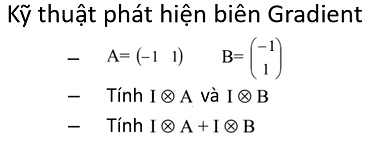

In [ ]:
def phep_gradient(I):
    A = np.array([
        [-1, 1],
    ], dtype=np.float32)
    B = np.array([
        [-1], [1],
    ], dtype=np.float32)
    IxA = phep_cuon_2(I, A)
    IxB = phep_cuon_2(I, B)
    I_kq = IxA + IxB
    return I_kq, IxA, IxB

Ta chạy thử với một ảnh tự tạo:

In [ ]:
I = np.array([
    [0, 0, 0, 0],
    [0, 3, 3, 3],
    [0, 3, 3, 3],
    [0, 3, 3, 3]
], dtype=np.uint8)
print("anh ban dau:")
print(I)

I_kq, IxA, IxB = phep_gradient(I)
print("I cuon A:")
print(IxA)
print("I cuon B:")
print(IxB)
print("anh ket qua:")
print(I_kq)

anh ban dau:
[[0 0 0 0]
 [0 3 3 3]
 [0 3 3 3]
 [0 3 3 3]]
I cuon A:
[[ 0.  0.  0. inf]
 [ 3.  0.  0. inf]
 [ 3.  0.  0. inf]
 [ 3.  0.  0. inf]]
I cuon B:
[[ 0.  3.  3.  3.]
 [ 0.  0.  0.  0.]
 [ 0.  0.  0.  0.]
 [inf inf inf inf]]
anh ket qua:
[[ 0.  3.  3. inf]
 [ 3.  0.  0. inf]
 [ 3.  0.  0. inf]
 [inf inf inf inf]]


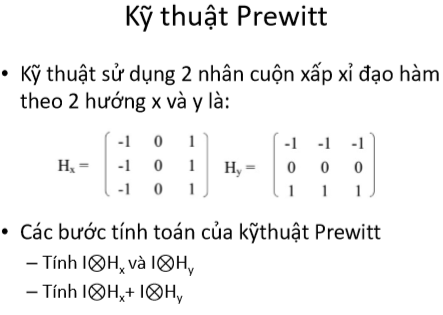

In [ ]:
def phep_prewitt(I):
    Hx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1],
    ], dtype=np.float32)
    Hy = np.array([
        [-1, -1, -1],
        [0, 0, 0],
        [1, 1, 1],
    ], dtype=np.float32)
    IxHx = phep_cuon_2(I, Hx)
    IxHy = phep_cuon_2(I, Hy)
    I_kq = IxHx + IxHy
    return I_kq, IxHx, IxHy

Ta chạy thử với một ảnh tự tạo:

In [ ]:
I = np.array([
    [0, 0, 0, 0, 0, 0],
    [5, 5, 5, 5, 0, 0],
    [5, 5, 5, 5, 0, 0],
    [5, 5, 5, 5, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0]
], dtype=np.uint8)
print("anh ban dau:")
print(I)

I_kq1, IxHx, IxHy = phep_prewitt(I)
print("I cuon Hx:")
print(IxHx)
print("I cuon Hy:")
print(IxHy)
print("anh ket qua:")
print(I_kq1)

anh ban dau:
[[0 0 0 0 0 0]
 [5 5 5 5 0 0]
 [5 5 5 5 0 0]
 [5 5 5 5 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]
I cuon Hx:
[[  0.   0. -10. -10.  inf  inf]
 [  0.   0. -15. -15.  inf  inf]
 [  0.   0. -10. -10.  inf  inf]
 [  0.   0.  -5.  -5.  inf  inf]
 [ inf  inf  inf  inf  inf  inf]
 [ inf  inf  inf  inf  inf  inf]]
I cuon Hy:
[[ 15.  15.  10.   5.  inf  inf]
 [  0.   0.   0.   0.  inf  inf]
 [-15. -15. -10.  -5.  inf  inf]
 [-15. -15. -10.  -5.  inf  inf]
 [ inf  inf  inf  inf  inf  inf]
 [ inf  inf  inf  inf  inf  inf]]
anh ket qua:
[[ 15.  15.   0.  -5.  inf  inf]
 [  0.   0. -15. -15.  inf  inf]
 [-15. -15. -20. -15.  inf  inf]
 [-15. -15. -15. -10.  inf  inf]
 [ inf  inf  inf  inf  inf  inf]
 [ inf  inf  inf  inf  inf  inf]]


# Thử nghiệm với ảnh thông thường đọc từ file

Ta đọc file dạng ảnh xám:

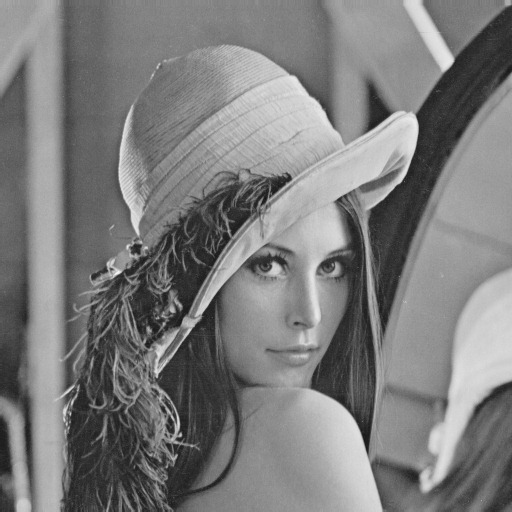

In [ ]:
I1 = cv2.imread("/content/lena.jpg", cv2.IMREAD_GRAYSCALE)
cv2_imshow(I1)

Ta tính với Prewitt

In [ ]:
I1_kq, IxHx, IxHy = phep_prewitt(I1)

# in một số điểm ảnh kết quả
print(I1_kq[10:15, 10:15])

[[ -8. -10.  -3.   7.  -3.]
 [ -7. -15.  -3.  14.   7.]
 [  2. -10.   6.  17.  11.]
 [  4.  -9.   5.  -1.  -8.]
 [  1.  -8.   0.  -5.  -6.]]


Do kết quả là ảnh số thực nên không thể hiển thị trực tiếp. Ta sẽ cần một phép chuyển đổi để hiển thị được kết quả.

Do bản chất việc tính toán là làm nổi biên, do đó ta sẽ hiển thị thông qua phân ngưỡng giá trị tuyệt đối các điểm trong ảnh kết quả.

In [ ]:
# I_e: ảnh biên kết quả được tính (ảnh số thực)
# theta: ngưỡng
def sinh_anh_hien_thi_bien(I_e, theta):
    I_kq = np.zeros(I_e.shape, np.uint8)
    for i in range(I_e.shape[0]):
        for j in range(I_e.shape[1]):
            I_kq[i,j] = 255 if abs(I_e[i,j]>theta) else 0
    return I_kq


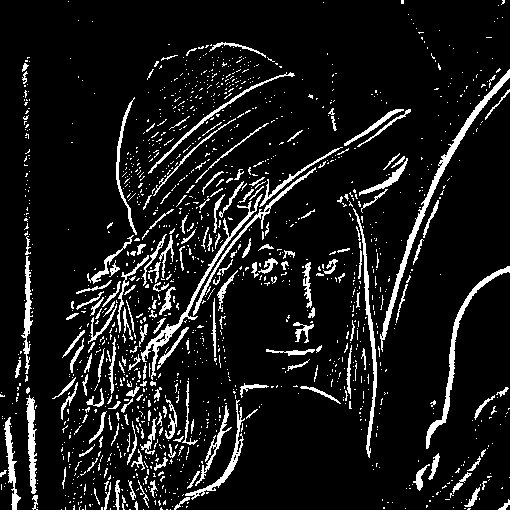

In [ ]:
# biên prewitt với xét ngưỡng = 50
I_view = sinh_anh_hien_thi_bien(I1_kq, 50)
cv2_imshow(I_view)

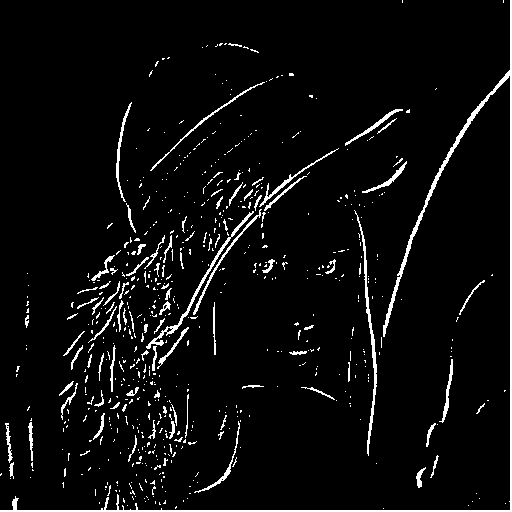

In [ ]:
# biên prewitt với xét ngưỡng = 100
I_view1 = sinh_anh_hien_thi_bien(I1_kq, 100)
cv2_imshow(I_view1)

# Một số bài tập thực hành



**Câu 1:** Thực hành với Sobel:

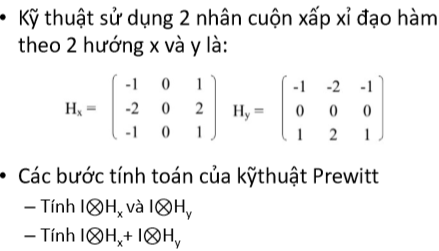

**Câu 2:** Thực hành với kỹ thuật La bàn

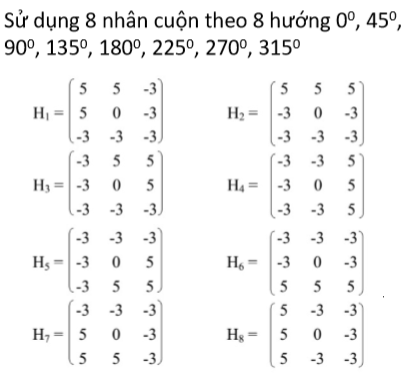